# Construcción de la matriz de proyección binaria

Continuaremos utilizando la matriz $X_{\text{fantoma}}$ y su versión vectorizada $x_{\text{fantoma}}$ construidas en el Ejercicio 1. El objetivo de este ejercicio es reunir las máscaras de distintos rayos en una única matriz de proyección $A$. Para cada rayo $r$, vectorizaremos su máscara $M_r$ por filas y utilizaremos el vector resultante como la fila $a_r^T$ de $A$. De este modo, si se generan $m$ rayos para una imagen de $n \times n$ píxeles, entonces $A \in \mathbb{R}^{m \times n^2}$.



In [2]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


#Matriz de 8x8 que representa el fantoma
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

# Vector de 64 elementos que representa el fantoma
x_v_fantoma=X_fantoma.reshape(-1)


#### a) Implementar la función `matriz_proyeccion(n, direcciones)`. Para cada dirección $(\alpha, \beta)$, se deberán calcular los distintos valores de $s = \alpha i + \beta j$, ordenarlos de menor a mayor, construir la máscara correspondiente a cada uno y agregar su versión vectorizada como una fila de $A$.

#### b) Hacer que la función devuelva también una lista con el par $((\alpha, \beta), s)$ asociado a cada fila de $A$, respetando el orden de las direcciones recibidas.

In [3]:
# Como los notebooks tienen que ser autocontenidos, copiamos la función mascara_rayo del ejercicio 2
def mascara_rayo(n, direccion, s):
    M = np.zeros((n, n))                                     # matriz de ceros
    i, j = np.ogrid[:n, :n]                                  # índices de la matriz
    condicion = (i * direccion[0] + j * direccion[1] == s)   # píxeles cuyo centro cumple α·i + β·j = s
    M[condicion] = 1
    return M


def matriz_proyeccion(n, direcciones):
    i, j = np.indices((n, n))   # i[a, b] = a (fila), j[a, b] = b (columna)
    filas = []                  # filas de A, una por rayo
    rayos = []                  # par ((α, β), s) asociado a cada fila de A

    for (alfa, beta) in direcciones:
        # α·i + β·j para todos los píxeles a la vez: cada entrada indica a qué rayo pertenece ese píxel
        S = alfa * i + beta * j

        # Valores distintos de s, ordenados de menor a mayor: cada uno es un rayo
        valores_s = np.unique(S)

        for s in valores_s:
            M = mascara_rayo(n, (alfa, beta), s)   # máscara n x n del rayo
            filas.append(M.reshape(-1))            # vectorizada por filas -> fila de A
            rayos.append(((alfa, beta), int(s)))   # qué rayo es esta fila

    # Apila los vectores como filas: A es m x n²
    A = np.array(filas, dtype=float)
    return A, rayos

Para cada dirección $(\alpha, \beta)$, la función calcula $\alpha i + \beta j$ en todos los píxeles. Cada valor indica en qué rayo cae ese píxel, y como varios píxeles comparten rayo, los valores se repiten. `np.unique` se queda con cada valor una sola vez y los ordena de menor a mayor. Por eso no hace falta conocer de antemano los valores posibles de $s$, que pueden ser negativos.

Cada máscara se convierte en vector con `reshape(-1)`, igual que la imagen en el Ejercicio 1, y ese vector es una fila de $A$. Como las dos se aplanan de la misma forma, la posición $k$ de la fila y la posición $k$ de $x$ son el mismo píxel, y el producto de la fila por $x$ suma exactamente los píxeles del rayo.

La lista `rayos`. Se completa en el mismo paso en que se agrega cada fila de $A$, así que su elemento $r$ indica la dirección y el valor de $s$ de la fila $r$.


#### c) Aplicar la función con $n = 8$ y `direcciones = [(1, 0), (0, 1)]`. Verificar que se obtienen 16 rayos y que $A \in \mathbb{R}^{16 \times 64}$.


In [4]:
direcciones=[(1, 0), (0, 1)]
A, rayos=matriz_proyeccion(8, direcciones)

print("Rayos:", rayos)
print("Cantidad de rayos:", len(rayos))
print("Dimensión de A:", A.shape)
print("¿16 rayos y A de 16 x 64?", len(rayos) == 16 and A.shape == (16, 64))

Rayos: [((1, 0), 0), ((1, 0), 1), ((1, 0), 2), ((1, 0), 3), ((1, 0), 4), ((1, 0), 5), ((1, 0), 6), ((1, 0), 7), ((0, 1), 0), ((0, 1), 1), ((0, 1), 2), ((0, 1), 3), ((0, 1), 4), ((0, 1), 5), ((0, 1), 6), ((0, 1), 7)]
Cantidad de rayos: 16
Dimensión de A: (16, 64)
¿16 rayos y A de 16 x 64? True


Se obtienen 16 rayos porque cada dirección genera 8 rayos. Con $(1, 0)$ la ecuación es $i = s$ y con $(0, 1)$ es $j = s$, y en ambos casos $s$ toma los valores $0, \dots, 7$. $A$ tiene 64 columnas porque hay una por píxel ($n^2 = 64$), sin importar cuántas direcciones se usen.

#### d) Explicar qué representa una fila de $A$ y qué representa una columna. Visualizar la matriz mediante `plt.imshow` y explicar por qué contiene una gran cantidad de ceros.



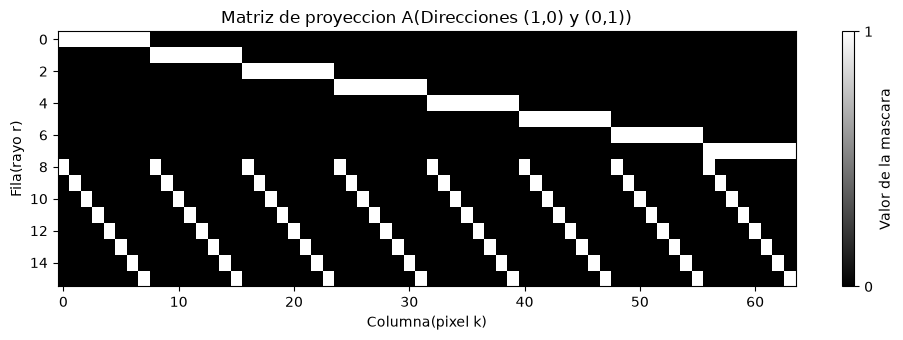

Entradas no nulas: 128 de 1024 (12.5 %)
Unos por fila: [8 8 8 8 8 8 8 8 8 8 8 8 8 8 8 8]
Unos por columna: [2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]


In [5]:
fig, ax= plt.subplots(figsize=(10, 3.5))
im = ax.imshow(A, cmap="gray",aspect="auto", interpolation="nearest")
ax.set_xlabel("Columna(pixel k)")
ax.set_ylabel("Fila(rayo r)")
ax.set_title("Matriz de proyeccion A(Direcciones (1,0) y (0,1))")
fig.colorbar(im, ax=ax, ticks=[0, 1], label="Valor de la mascara")
plt.tight_layout()
plt.savefig('figuras/ejercicio_03d.png', dpi=150)
plt.show()

# Proporción de entradas no nulas
no_nulos = np.count_nonzero(A)
print(f"Entradas no nulas: {no_nulos} de {A.size} ({100 * no_nulos / A.size:.1f} %)")
print("Unos por fila:", A.sum(axis=1).astype(int))
print("Unos por columna:", A.sum(axis=0).astype(int))

**Filas.** Cada fila de $A$ es un **rayo**, tiene una entrada por píxel ($n^2 = 64$), con un 1 en los píxeles que el rayo atraviesa y un 0 en el resto.

**Columnas.** Cada columna de $A$ es un **píxel**, tiene una entrada por rayo (16), con un 1 en los rayos que pasan por ese píxel. Como cada píxel está en exactamente un rayo de cada dirección, cada columna tiene dos unos, uno por la fila de la imagen y otro por la columna (por ejemplo, la columna 0 tiene unos en las filas 0 y 8).

la estructura del gráfico se explica con la fórmula $k = i\,n + j$ del Ejercicio 1

- Filas 0 a 7, dirección $(1, 0)$: cada rayo selecciona una fila de la imagen (rayos horizontales). Los píxeles de una misma fila son consecutivos en el vector, así que en $A$ se ven como un bloque de 8 unos seguidos que se va corriendo hacia la derecha. Por ejemplo, la fila 3 de $A$ tiene unos en los píxeles 24 a 31.
- Filas 8 a 15, dirección $(0, 1)$: cada rayo selecciona una columna de la imagen (rayos verticales). Los píxeles de una misma columna están separados de a $n = 8$ en el vector, así que en $A$ se ven como unos espaciados, que forman el patrón diagonal. Por ejemplo, la fila 8 tiene unos en los píxeles 0, 8, 16, …, 56.

Cada rayo atraviesa solo 8 de los 64 píxeles, así que cada fila tiene 8 unos y 56 ceros. Solo el 12.5 % de las entradas es distinto de cero, es decir $A$ es una matriz dispersa”.

#### e) Calcular las mediciones $b = A\,x_{\text{fantoma}}$. Verificar que sus primeras ocho componentes coinciden con `X_fantoma.sum(axis=1)` y las ocho restantes con `X_fantoma.sum(axis=0)`. Graficar ambos bloques como señales unidimensionales.

In [6]:
# Producto matriz-vector: una medición por rayo
b = A @ x_v_fantoma
print("b =", b)

sumas_filas = X_fantoma.sum(axis=1)      # una suma por cada fila de la imagen
sumas_columnas = X_fantoma.sum(axis=0)   # una suma por cada columna de la imagen

print("¿b[:8] coincide con las sumas por filas?   ", np.allclose(b[:8], sumas_filas))
print("¿b[8:] coincide con las sumas por columnas?", np.allclose(b[8:], sumas_columnas))

# Observaciones para el análisis
print("¿El fantoma es simétrico (X = Xᵀ)?", np.array_equal(X_fantoma, X_fantoma.T))
print(f"Suma de las mediciones horizontales: {b[:8].sum():.2f}")
print(f"Suma de las mediciones verticales:   {b[8:].sum():.2f}")

b = [0.  1.7 3.3 2.3 2.  2.4 1.4 0.  0.  1.7 3.3 2.3 2.  2.4 1.4 0. ]
¿b[:8] coincide con las sumas por filas?    True
¿b[8:] coincide con las sumas por columnas? True
¿El fantoma es simétrico (X = Xᵀ)? True
Suma de las mediciones horizontales: 13.10
Suma de las mediciones verticales:   13.10


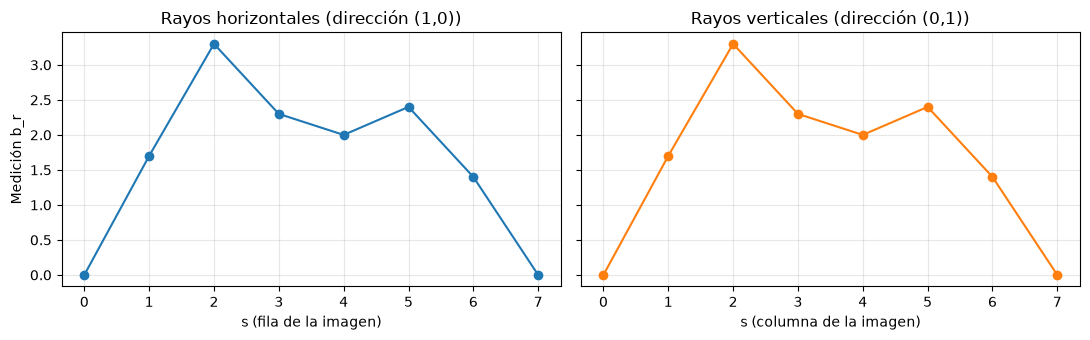

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)

axes[0].plot(range(8), b[:8], marker='o')
axes[0].set_title('Rayos horizontales (dirección (1,0))')
axes[0].set_xlabel('s (fila de la imagen)')
axes[0].set_ylabel('Medición b_r')
axes[0].set_xticks(range(8))
axes[0].grid(alpha=0.3)

axes[1].plot(range(8), b[8:], marker='o', color='tab:orange')
axes[1].set_title('Rayos verticales (dirección (0,1))')
axes[1].set_xlabel('s (columna de la imagen)')
axes[1].set_xticks(range(8))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('figuras/ejercicio_03e.png', dpi=150)
plt.show()

El producto matriz-vector $A\,x$ calcula, para cada fila, el producto punto $a_r^T x$, es decir, la suma de los píxeles que atraviesa el rayo $r$. Con estas dos direcciones, las primeras 8 mediciones son las sumas de cada fila de la imagen y las 8 restantes, las sumas de cada columna. 

Cada gráfico es una **proyección** del fantoma, es decir, el conjunto de mediciones que se obtiene para una dirección fija al recorrer las distintas posiciones $s$ del detector. En otras palabras, muestra cuánto atenúa el objeto en cada fila (o en cada columna). Las dos señales valen 0 en los extremos ($s = 0$ y $s = 7$), porque la primera y la última fila y columna del fantoma son ceros, es decir, ahí no hay objeto. El valor máximo está en $s = 2$, que es donde el rayo atraviesa la zona de 0.8.

Además, las dos señales son idénticas. Esto ocurre porque el fantoma es simétrico ($X = X^T$), es decir, la fila $i$ y la columna $i$ tienen los mismos valores. Es un ejemplo de lo visto en el Ejercicio 2d dos rayos distintos pueden dar la misma medición.

 Si se suman las 8 mediciones horizontales y, por otro lado, las 8 verticales, en los dos casos da 13.10. Esto ocurre porque ambas sumas recorren todos los píxeles de la imagen una sola vez, es decir, las dos son la atenuación total. Como esto vale para cualquier imagen, una fila de $A$ se puede escribir como combinación lineal de las demás, por lo que las 16 mediciones no son todas linealmente independientes.